In [1]:
import os
import sys
sys.path.insert(0, "../../Python/cellular_cycle") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
from numpy.linalg import norm
import datetime
import math
import multiprocess as mp
import time

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
DATADIR = Path('../../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [5]:
t = np.linspace(0, 1000, 1000001)
# t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 1

In [6]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/../../Python/model_data/parameters.csv')
del new_param['Stress']
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
F_n.1
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [7]:
initial_concentrations = pd.read_csv(os.getcwd() + '/../../Python/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

BAXm_0
BCL2_0


In [8]:
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run() #deterministic simulation

In [9]:
observables=['obsCycE','obsCdc20', 'obsCycA']; #plot Cyclin E, Cdc20 and Cyclin A

<Axes: xlabel='Time (h)', ylabel='Concentration'>

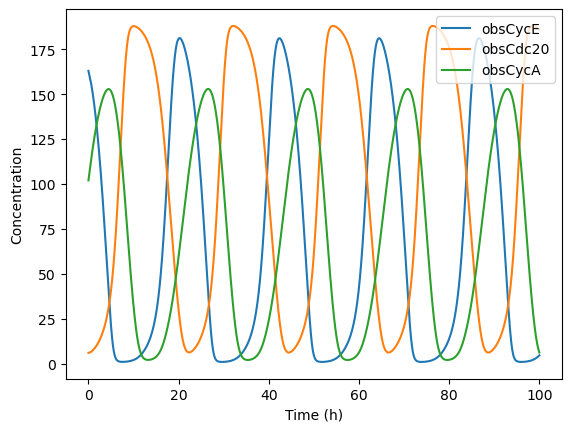

In [10]:

plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,100000), legend=True)


In [11]:
from scipy.signal import find_peaks

In [12]:
FAKs = list(np.linspace(0.4,0.6,50))
tmp = list(np.linspace(0.6,1,50))
FAKs.extend(tmp)

In [13]:
AKTs = list(np.linspace(0.3,0.6,50))
tmp = [0.6]*50
AKTs.extend(tmp)
ERKs = [0.2]*100

In [14]:
AKTt=[0.3,0.6]
ERKt=[0.2,0.2]
FAKt=[0.4,0.6]

In [50]:
integrator_options = {
    "rtol": 1e-10,
    "atol": 1e-10
}

In [56]:
points=2

In [57]:
def run_lyaps(AKT, ERK, FAK, np=np, model=model, points=points, ScipyOdeSimulator=ScipyOdeSimulator, find_peaks=find_peaks,
             integrator_options=integrator_options, norm=norm, math=math):
    model.parameters['AKT'].value = AKT
    model.parameters['ERK'].value = ERK
    model.parameters['FAK'].value = FAK
    ep = 0.001*200
    t = np.linspace(0, 1000, 1000001)
    all_logz = dict.fromkeys(list(range(1,points+1)))
    
    for kk in range(points):
        sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python', integrator_options=integrator_options).run()
        y_out = sim_ode.all
        
        peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence = 0.6, distance = 10)
        new_y = y_out[peaks_cdc[-11]:peaks_cdc[-2]]

        variable_range=y_out[peaks_cdc[-11]:peaks_cdc[-10]]
        tmp_loc = (round(len(variable_range)/(kk+1))*(kk))
        
        Initial_1 = variable_range[tmp_loc]
        Initial_1 = [val+ep for val in Initial_1]
        
        prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
                 'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
                 'Cdc20_0']
        prot_init = {prots[i]: Initial_1[i] for i in range(len(prots))}
        
        for key in prot_init.keys():
            model.parameters[key].value = prot_init[key] / model.parameters['omega'].value   
            
        sim_ode1 = ScipyOdeSimulator(model, t, verbose=False, compiler='python', integrator_options=integrator_options).run()
        y_out1 = sim_ode1.observables        
        
        z=[0]*(round((len(y_out1)/2000))+1)
        n=0
        for i in range(0, len(y_out1), 2000):
            dists = [0]*len(variable_range)
            for j in range(0, len(variable_range)):
                dif = [variable_range[j][num]/200-y_out1[i][num]/200 for num in range(19)]
                dists[j] = norm(dif)

            z[n] = min(dists)
            n=n+1
        
        logz = [math.log(num) for num in z]
        all_logz[kk+1] = logz
        
    return all_logz
                
        

In [58]:
start = time.time()
all_logz = run_lyaps(AKTs[0], ERKs[0], FAKs[0])
end = time.time()
print(end - start)

2205.151499271393


In [53]:
start = time.time()
with mp.Pool(processes = 12) as p:
    results = p.starmap(run_lyaps, [(0.3,0.2,0.4),(0.6,0.2,0.6)])
end = time.time()
print(end - start)

1242.98073720932


In [59]:
all_logz

{1: [-5.435535789398926,
  -3.8960978290063846,
  -3.248257314031946,
  -2.8625183510678003,
  -3.138953207506187,
  -2.822535680480711,
  -2.5573891538445137,
  -2.3494166731045576,
  -2.1651382151021483,
  -1.9907748689514002,
  -1.8205067813296951,
  -1.6516604508923325,
  -1.482896363177912,
  -1.3136576499246229,
  -1.1442305400889243,
  -0.9767209513923256,
  -0.8249913883300838,
  -0.8452796647522796,
  -0.9028262727401752,
  -0.964356336815495,
  -1.0248485393917386,
  -1.0824923856053823,
  -1.1364021247979805,
  -1.1855123992217538,
  -1.2277677123033137,
  -1.2673135423246393,
  -1.323533851133432,
  -1.3444194633245092,
  -0.9681013576062507,
  -1.4836791010471433,
  -1.5524209699464382,
  -1.3652247422076402,
  -1.4255817284269836,
  -1.9718604534026165,
  -2.301728318203304,
  -2.164962852306829,
  -2.4203556598489984,
  -2.4575519508392016,
  -2.901632826779856,
  -2.6189490353263833,
  -2.399279583412915,
  -2.21097463219129,
  -2.0319035664718,
  -1.855055273249738,
  

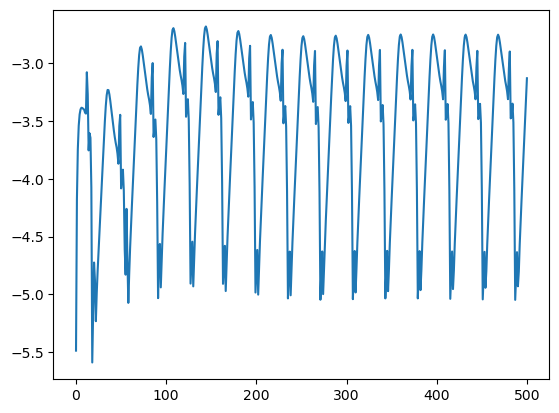

In [62]:
plt.plot(all_logz[2])

In [19]:
start = time.time()
with mp.Pool(processes = 12) as p:
    results = p.starmap(run_lyaps, [(AKT, ERK, FAK) for AKT in AKTt for ERK in ERKt for FAK in FAKt])
end = time.time()
print(end - start)

NameError: name 'model' is not defined

In [ ]:
len(all_logz)

In [2]:
def func(a, b):
    return a + b

In [3]:
a_args = [1,2,3]
second_arg = 1
with mp.Pool() as pool:
    L = pool.starmap(func, [(1, 1), (2, 1), (3, 1)])

In [4]:
L

[2, 3, 4]

In [ ]:
model.parameters['AKT'].value = AKTs[0]
model.parameters['ERK'].value = ERKs[0]
model.parameters['FAK'].value = FAKs[0]

In [ ]:
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python', integrator_options=integrator_options).run()
y_out = sim_ode.observables

In [ ]:
ep = 0.001*200


In [ ]:
peaks_cdc, _ = find_peaks(y_out['obsCdc20'], prominence = 0.6, distance = 10)
new_y = y_out[peaks_cdc[-11]:peaks_cdc[-2]]


In [ ]:
variable_range=y_out[peaks_cdc[-11]:peaks_cdc[-10]]

In [ ]:
len(variable_range)

In [ ]:
kk=1
tmp_loc = (round(len(variable_range)/kk)*(kk-1))


In [ ]:
Initial_1 = new_y[tmp_loc]
Initial_1

In [ ]:
Initial_1 = [val+ep for val in Initial_1]
new_y_ab = new_y[tmp_loc:]

In [ ]:
Initial_1

In [ ]:
# prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
#  'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
#  'Cdc20_0', 'BAX_0', 'BAXmBCL2_0', 'BH3_0', 'BH3BCL2_0', 'BAXm_0', 'BCL2_0']
# prot_init = {prots[i]: Initial_1[i] for i in range(len(prots))}
# #del prot_init['BAXm_0']
# #del prot_init['BCL2_0']

In [ ]:
prots = ['Skp2_0', 'p21_0', 'p21p_0', 'cdh1act_0', 'cdh1inact_0', 'Myc_0', 'CycD_0', 'CycDp21_0', 'pRb_0',
 'pRbp_0', 'E2F_0', 'pRbE2F_0', 'CycE_0', 'CycEp21_0', 'CycA_0', 'CycAp21_0', 'CycB_0', 'CycBp21_0',
 'Cdc20_0']
prot_init = {prots[i]: Initial_1[i] for i in range(len(prots))}
#del prot_init['BAXm_0']
#del prot_init['BCL2_0']

In [ ]:
model.parameters['Cdc20_0'].value

In [ ]:
for key in prot_init.keys():
    model.parameters[key].value = prot_init[key] / model.parameters['omega'].value

In [ ]:
model.parameters['Cdc20_0'].value

In [ ]:
t = np.linspace(0, 1000, 1000001)
#t = np.linspace(0, 10, 10001)

In [ ]:
sim_ode1 = ScipyOdeSimulator(model, t, verbose=False, compiler='python', integrator_options=integrator_options).run()
y_out1 = sim_ode1.observables


In [ ]:
plt.plot(variable_range['obsCdc20'][0:1200]/200)
plt.plot(y_out1['obsCdc20'][0:1200]/200)

In [ ]:
len(y_out1)

In [ ]:
i = 0
j = 0
dif = [variable_range[j][num]/200-y_out1[i][num]/200 for num in range(19)]
norm(dif)

In [ ]:
dif

In [ ]:
dists = [0]*len(variable_range)
for j in range(0, len(variable_range)):
    dif = [variable_range[j][num]/200-y_out1[i][num]/200 for num in range(19)]
    dists[j] = norm(dif)

In [ ]:
plt.plot(dists)

In [ ]:
min(dists)

In [ ]:
z=[0]*(round((len(y_out1)/2000))+1)
n=0

In [ ]:
for i in range(0, len(y_out1), 2000):
    dists = [0]*len(variable_range)
    for j in range(0, len(variable_range)):
        dif = [variable_range[j][num]/200-y_out1[i][num]/200 for num in range(19)]
        dists[j] = norm(dif)
    
    z[n] = min(dists)
    n=n+1
    if n%100 == 0:
        print(n)

In [ ]:
tmp = [num+0.0001 for num in z]

In [ ]:
logz = [math.log(num) for num in z]
plt.plot(logz)

In [ ]:
z